PCA con scikit-learn

[[-1 -1]
 [ 0  2]
 [ 2  0]
 [ 3  3]]
[[-1. -1.]
 [ 1.  1.]
 [ 1.  1.]
 [ 3.  3.]]


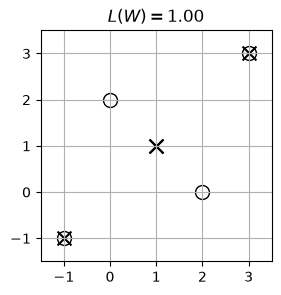

In [ ]:
import numpy as np; import matplotlib.pyplot as plt
X = np.array([ [-1, -1], [0, 2], [2, 0], [3, 3] ])
N = len(X)

print(X) #matriz de datos
K = 1
_, _, Vt = np.linalg.svd(X - X.mean(0)) 
W = Vt[:K, :].T #matriz de proyeccion
Z = X @ W
hX = Z @ W.T #deconstruccion
print(hX)

L = np.square(X - hX).sum(axis=1).mean() #error de reconstruccion
fig, ax = plt.subplots(figsize=(3, 3))
ax.set_aspect("equal")
plt.axis([-1.5, 3.5, -1.5, 3.5]); 
plt.grid(True); ax.set_title(f'$L(W)={L:.2f}$')
plt.scatter(*X.T, facecolor='white', edgecolor='k', s=100)
plt.scatter(*hX.T, facecolor='black', s=100, marker='x')


[[0.70710678 0.70710678]]
[1. 1.]


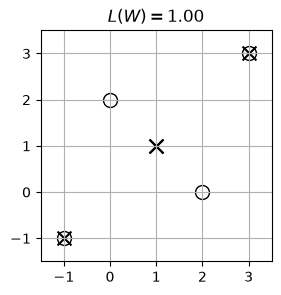

In [ ]:
import numpy as np; import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
X = np.array([ [-1, -1], [0, 2], [2, 0], [3, 3] ])
N = len(X)

K = 1 #cuantos componentes quiero 
pca = PCA(n_components=K).fit(X - X.mean(0)) #fit es para entrenar, se le pasan las muestras 
print(pca.components_) #la matrizque ha encontrado
print(pca.mean_) #media de los datos de la matriz q le pasamos, ya lo hemos pasado centrado aunque pCA tambien lo puede hacer solo
Z = pca.transform(X)
hX = pca.inverse_transform(Z)
L = np.square(X - hX).sum(axis=1).mean()
fig, ax = plt.subplots(figsize=(3, 3))
ax.set_aspect("equal")
plt.axis([-1.5, 3.5, -1.5, 3.5])
plt.grid(True)
ax.set_title(f'$L(W)={L:.2f}$')
plt.scatter(*X.T, facecolor='white', edgecolor='k', s=100)
plt.scatter(*hX.T, facecolor='black', s=100, marker='x')


MNIST

In [9]:
import numpy as np; import datasets
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy"); ds


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

In [10]:

train0 = ds['train'][0]
train0['image'].shape, train0['image'].dtype, train0['label']


((28, 28), dtype('uint8'), np.int64(5))

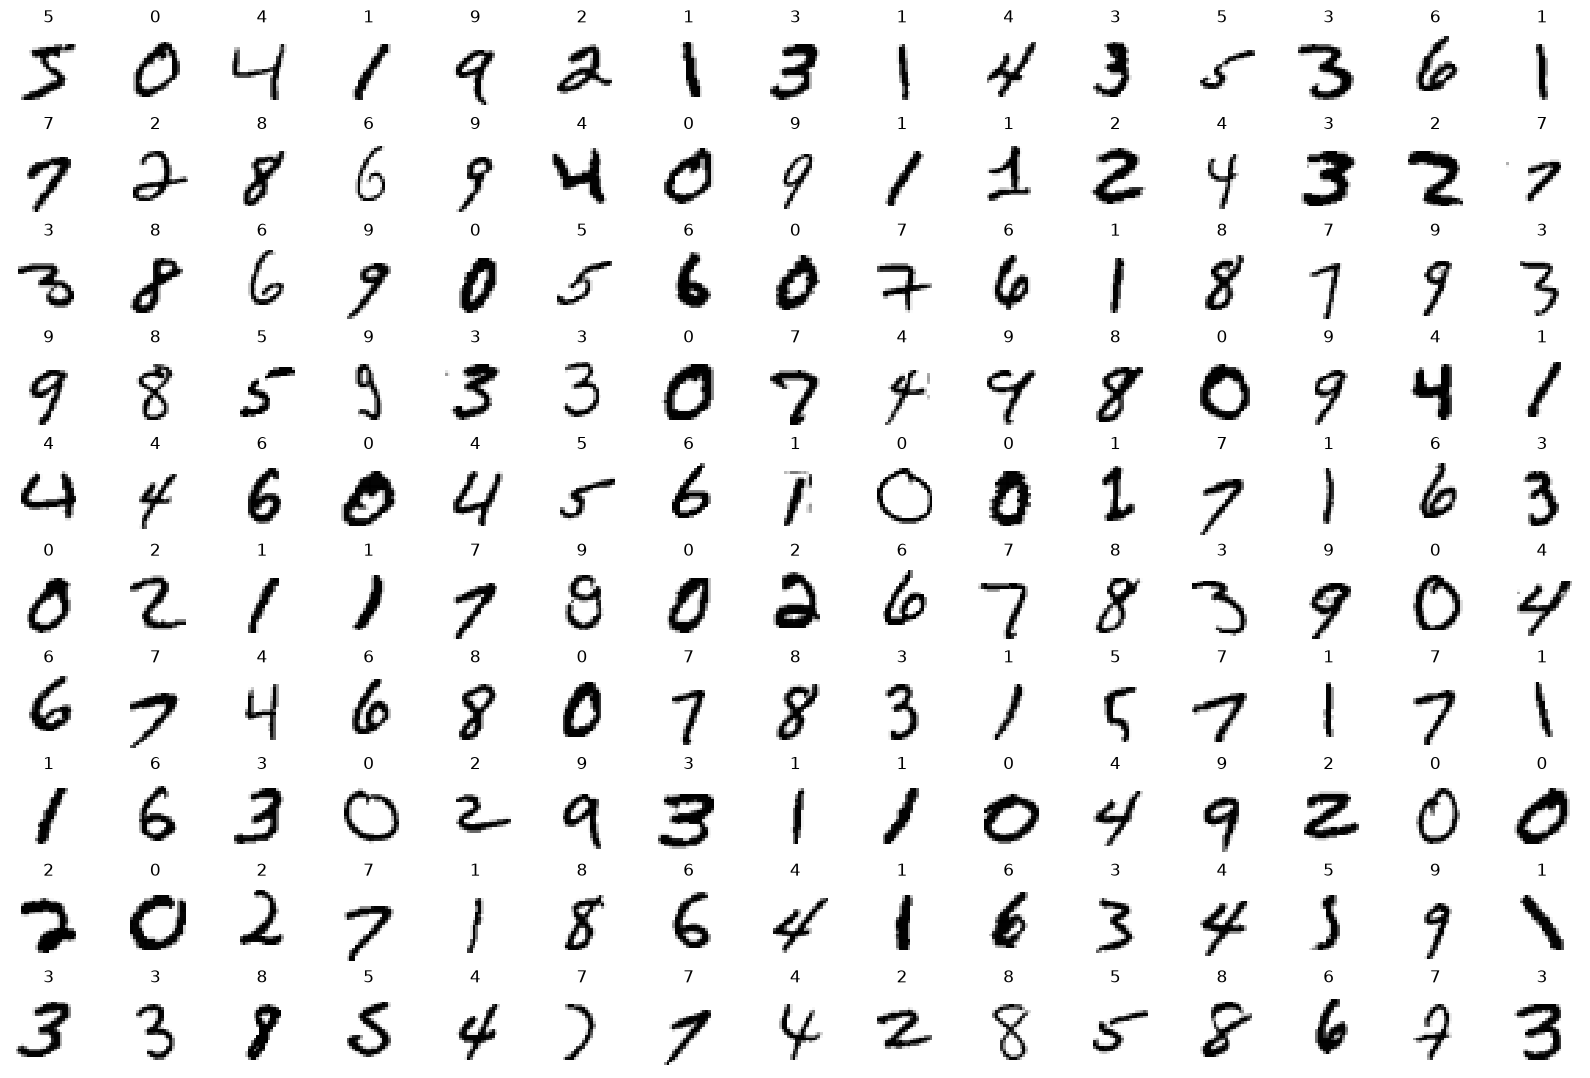

In [11]:
import matplotlib.pyplot as plt; nrows = 10; ncols = 15; N = nrows * ncols
_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 16*nrows/ncols), constrained_layout=True)
for ax, x, y in zip(axs.flat, ds['train'][:N]['image'], ds['train'][:N]['label']):
 ax.set_axis_off(); ax.imshow(x, cmap=plt.cm.gray_r, interpolation="none"); ax.set_title(y)


In [ ]:

import numpy as np; import datasets
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")


X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

In [14]:
ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 784), dtype=float32)

estudio de error de construccion probando diferentes dimensioens de k

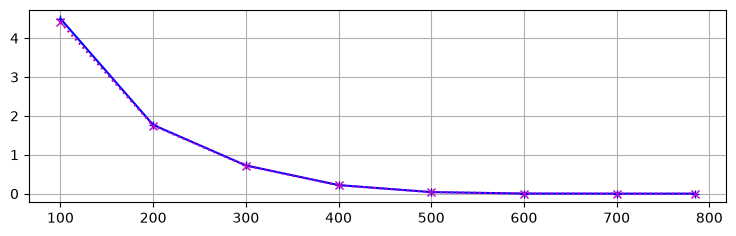

In [15]:
import matplotlib.pyplot as plt; from sklearn.decomposition import PCA
max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train) #transforma 
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])

L_train = np.empty_like(Ks, dtype=float)
L_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks): #prueba todas las k's pero no recalcula pca. calcula el pca de la K mas grande
 Z_train_K = Z_train.copy(); Z_train_K[:, K:] = 0.0; hX_train = pca.inverse_transform(Z_train_K)
 L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()
 Z_test_K = Z_test.copy(); Z_test_K[:, K:] = 0.0; hX_test = pca.inverse_transform(Z_test_K)
 L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()
plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m');


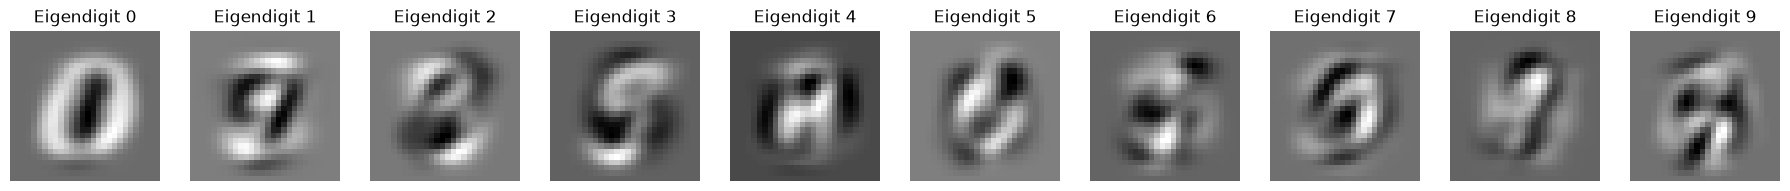

In [ ]:

K = 400; pca = PCA(n_components=K).fit(X_train); nrows, ncols = 1, 10
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)
for i in range(min(K, nrows * ncols)):
 ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"Eigendigit {i}")
 ax.imshow(pca.components_[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")

#son los pesos de cada cosa. pesos que sean 0 son irrelevantes 


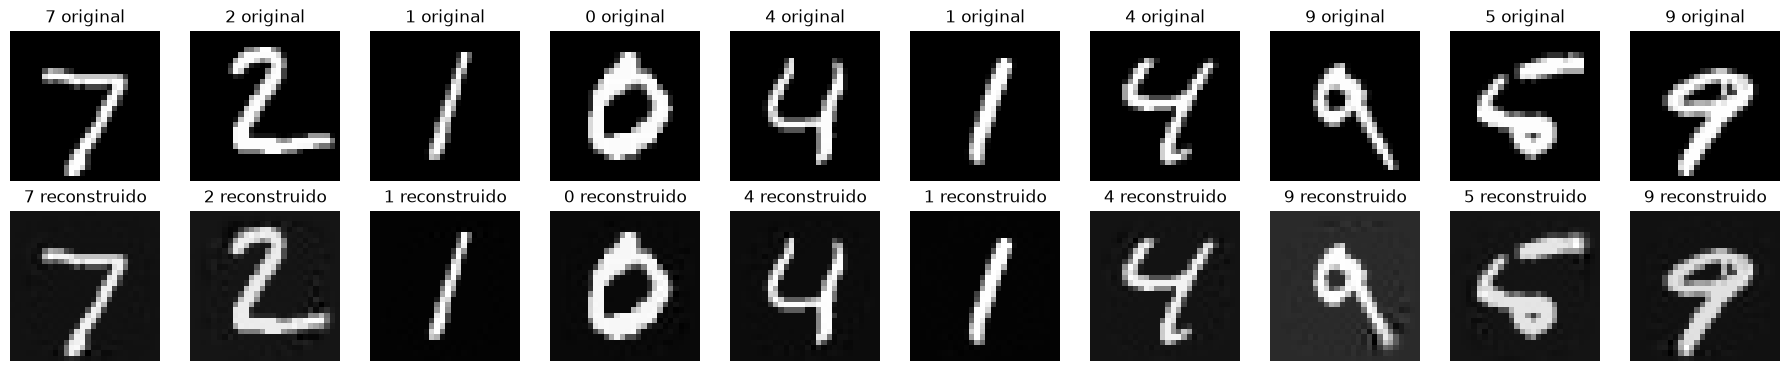

In [ ]:
ncols = 10; Z_test = pca.transform(X_test[:ncols]); hX_test = pca.inverse_transform(Z_test)
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)
for i in range(ncols):
 ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} original")
 ax.imshow(X_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")
 ax = axs.flat[ncols + i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} reconstruido")
 ax.imshow(hX_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")


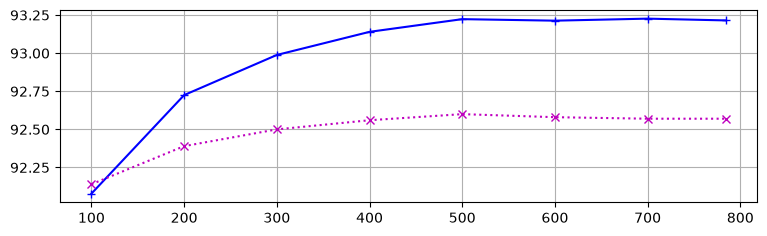

In [18]:

from sklearn.linear_model import LogisticRegression

max_K = np.min(X_train.shape); pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train); Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])
acc_train = np.empty_like(Ks, dtype=float); acc_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
 clf = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], y_train) #metaparametros
 acc_train[i] = clf.score(Z_train[:, :K], y_train)
 acc_test[i] = clf.score(Z_test[:, :K], y_test)
plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m');

Ejercicios

aplica PCA a Fashion-MNIST y CIFAR-10 siguiendo el ejemplo dado para MNIST

Fashion-MNIST

In [19]:
import numpy as np; import datasets
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy"); ds

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

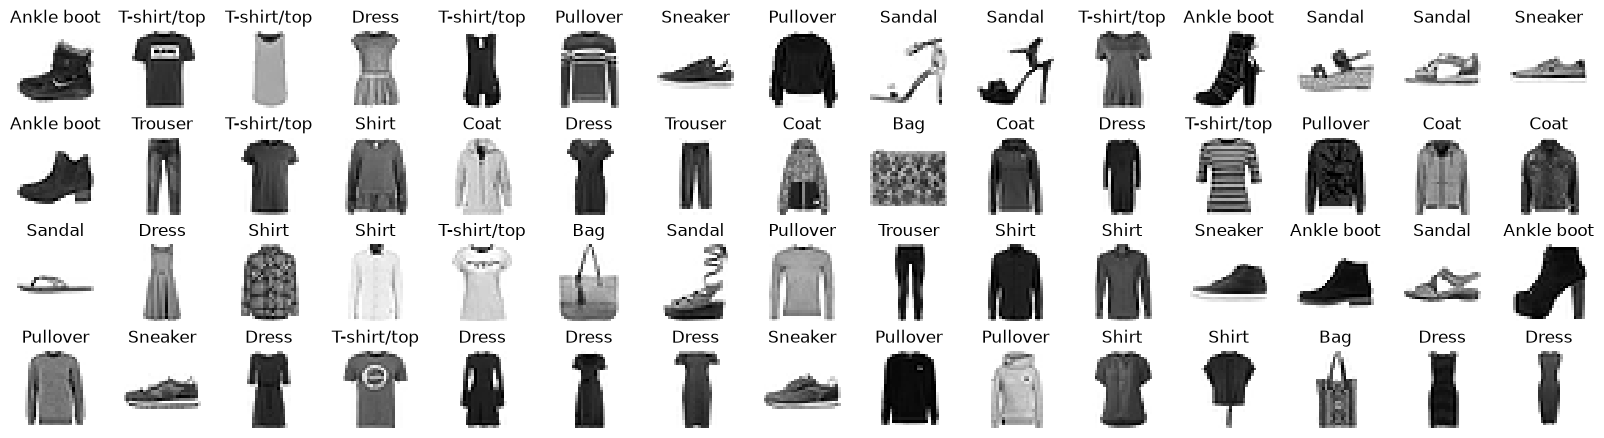

In [20]:
import matplotlib.pyplot as plt; nrows = 4; ncols = 15; N = nrows * ncols
labels = ("T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot")
_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 16*nrows/ncols), constrained_layout=True)
for ax, x, y in zip(axs.flat, ds['train'][:N]['image'], ds['train'][:N]['label']):
 ax.set_axis_off(); ax.imshow(x, cmap=plt.cm.gray_r, interpolation="none"); ax.set_title(labels[y])

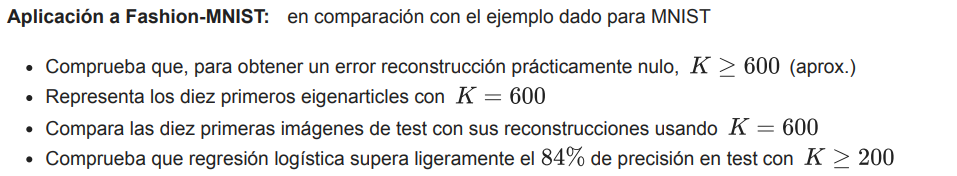

In [40]:
import numpy as np; import datasets
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)


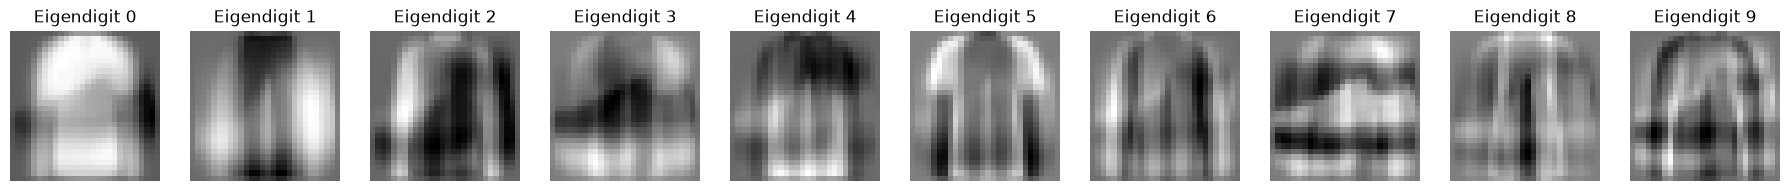

In [41]:
K = 600; pca = PCA(n_components=K).fit(X_train); nrows, ncols = 1, 10
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)
for i in range(min(K, nrows * ncols)):
 ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"Eigendigit {i}")
 ax.imshow(pca.components_[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")


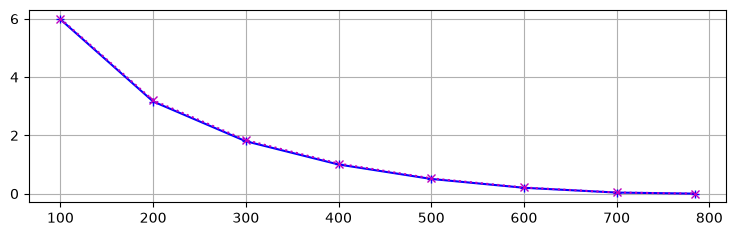

In [42]:
import matplotlib.pyplot as plt; from sklearn.decomposition import PCA
max_K = np.min(X_train.shape); pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train); Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])
L_train = np.empty_like(Ks, dtype=float); L_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
 Z_train_K = Z_train.copy(); Z_train_K[:, K:] = 0.0; hX_train = pca.inverse_transform(Z_train_K)
 L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()
 Z_test_K = Z_test.copy(); Z_test_K[:, K:] = 0.0; hX_test = pca.inverse_transform(Z_test_K)
 L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()
plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m')

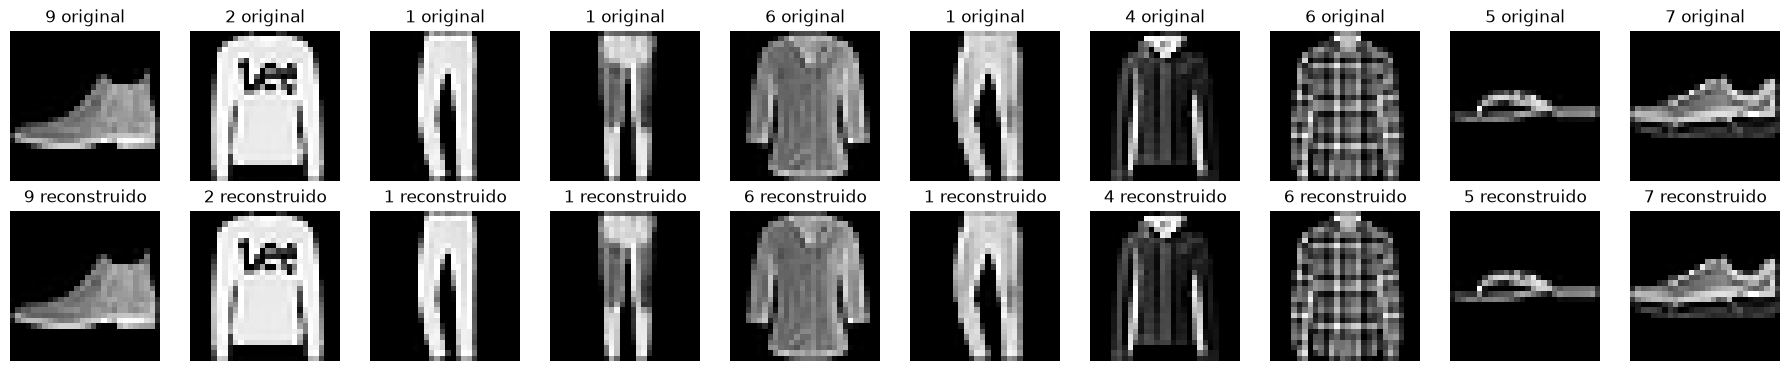

In [43]:
ncols = 10; Z_test = pca.transform(X_test[:ncols]); hX_test = pca.inverse_transform(Z_test)
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)
for i in range(ncols):
 ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} original")
 ax.imshow(X_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")
 ax = axs.flat[ncols + i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} reconstruido")
 ax.imshow(hX_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

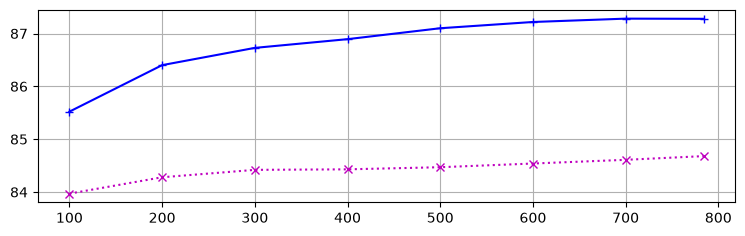

In [45]:



from sklearn.linear_model import LogisticRegression
max_K = np.min(X_train.shape); pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train); Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])
acc_train = np.empty_like(Ks, dtype=float); acc_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
 clf = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], y_train)
 acc_train[i] = clf.score(Z_train[:, :K], y_train)
 acc_test[i] = clf.score(Z_test[:, :K], y_test)
plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m')


CIFAR - 10

In [46]:
import numpy as np; import datasets
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy"); ds


DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})

In [47]:

train0 = ds['train'][0]
train0['img'].shape, train0['img'].dtype, train0['label']


((32, 32, 3), dtype('uint8'), np.int64(0))

In [50]:
import numpy as np; import datasets
X_train = ds['train'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)